In [6]:
import tskit
import numpy as np
import pandas as pd
import sys
sys.path.append("/Users/jameskitchens/Documents/GitHub/terracotta")
import terracotta as tct
import importlib
importlib.reload(tct)
import matplotlib.pyplot as plt


demes = pd.read_csv("dataset_glacial_small/demes.tsv", sep="\t")
connections = pd.read_csv("dataset_glacial_small/connections.tsv", sep="\t")
world_map = tct.WorldMap(demes, connections)

ts = tskit.load("/Users/jameskitchens/Desktop/slim.trees")

In [7]:
for node in ts.first().roots:
    print(ts.population(ts.node(node).population).metadata["name"], ts.node(node).time)

p7 1000.0
p9 1000.0
p14 1000.0
p15 1000.0
p17 1000.0


In [8]:
nodes = ts.tables.nodes
deepest_roots = np.where(nodes.time == max(nodes.time))[0]
tree = ts.first()
samples = []
for root in deepest_roots:
    samples.extend(list(tree.leaves(root)))
random_samples = np.random.choice(samples, size=25, replace=False)
ts = ts.simplify(samples=random_samples, keep_unary=True)

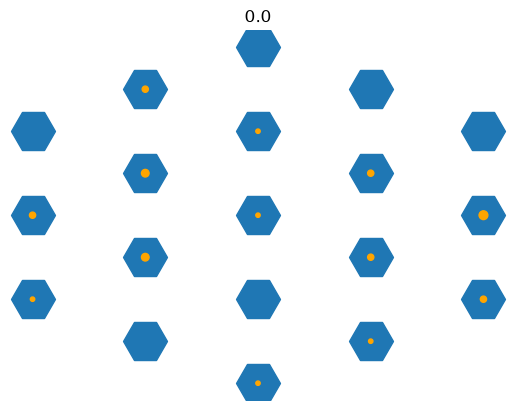

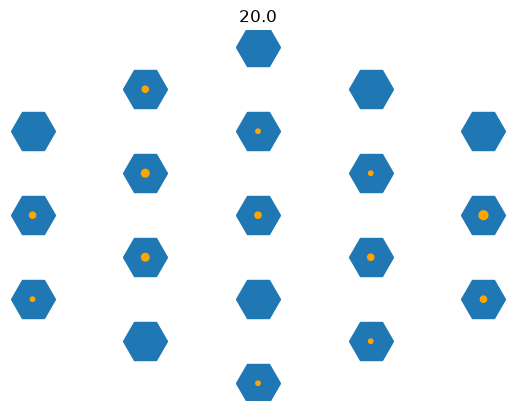

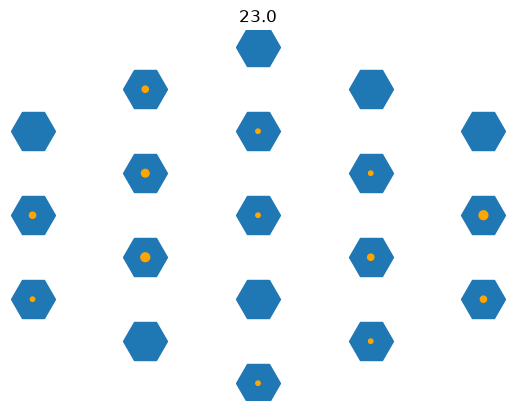

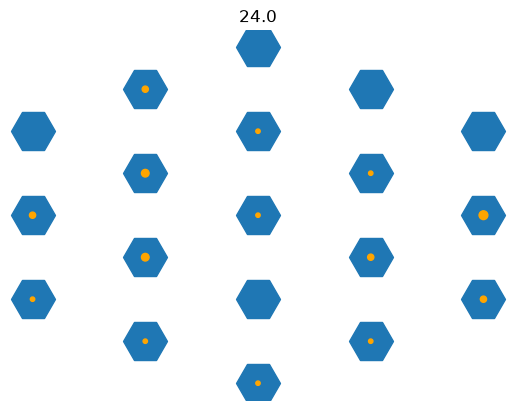

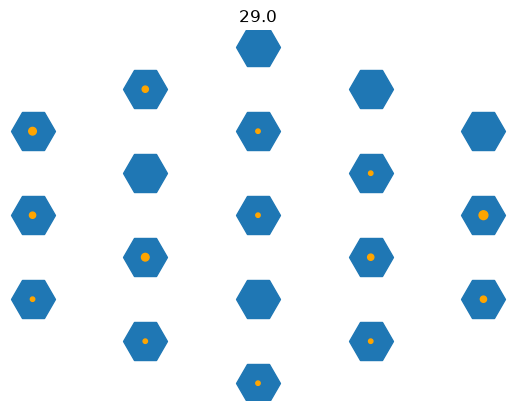

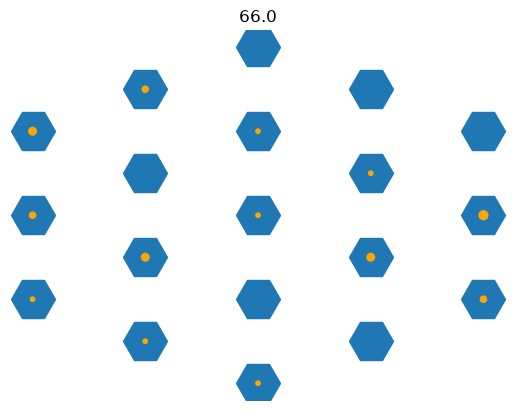

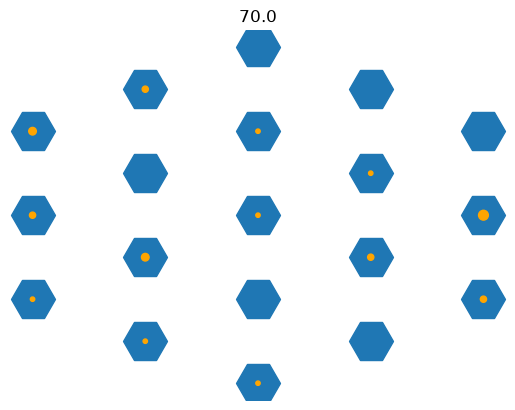

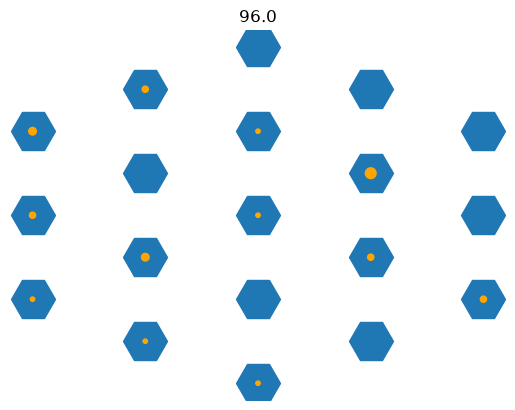

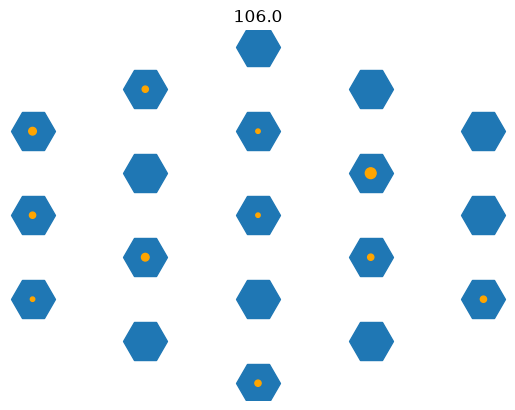

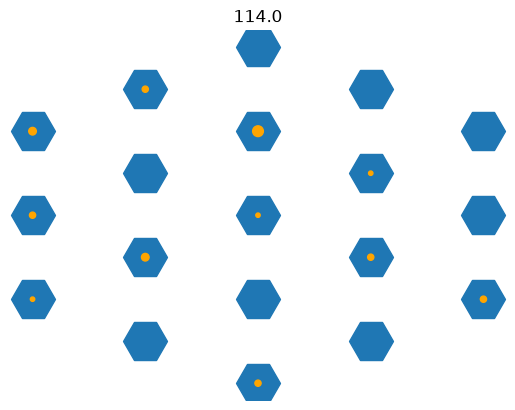

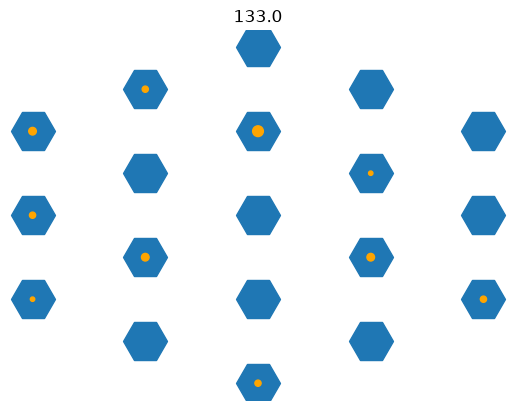

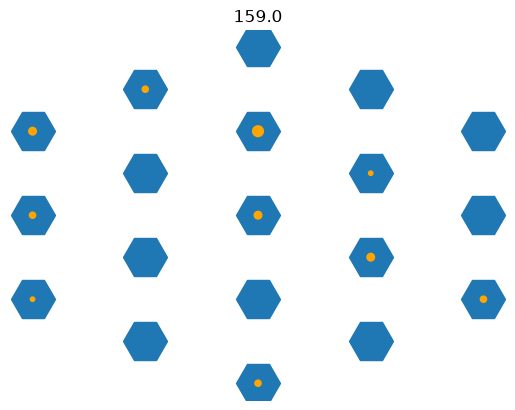

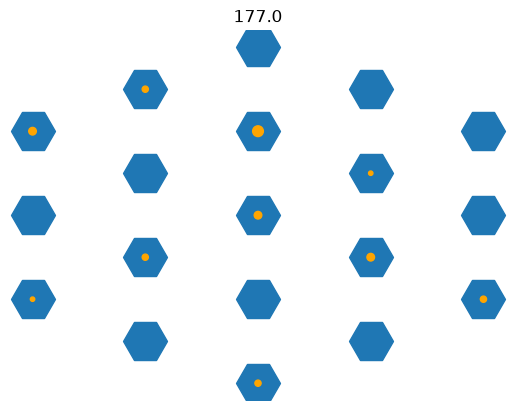

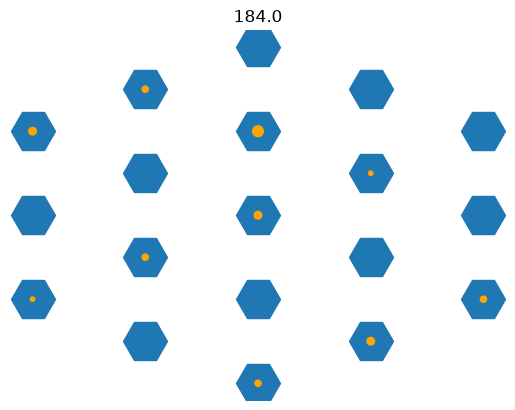

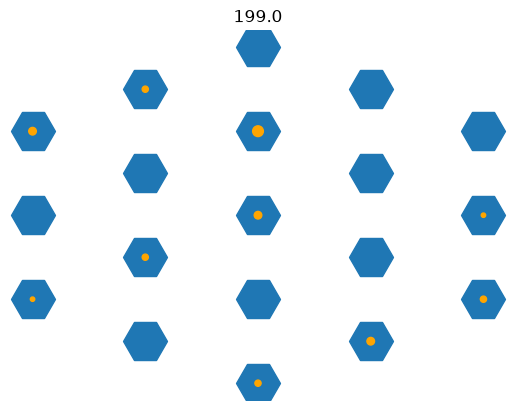

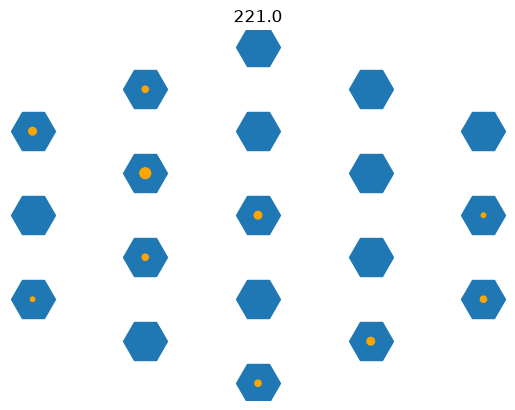

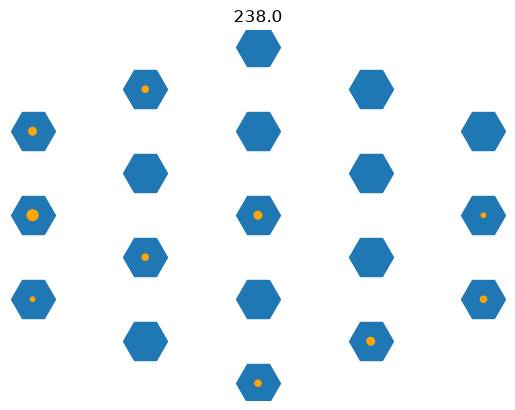

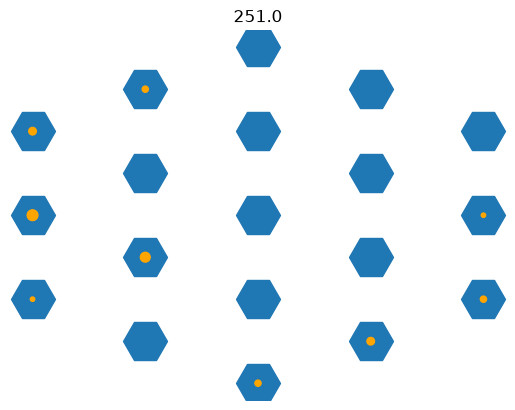

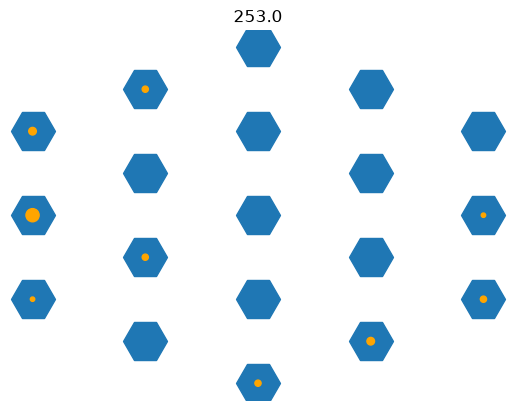

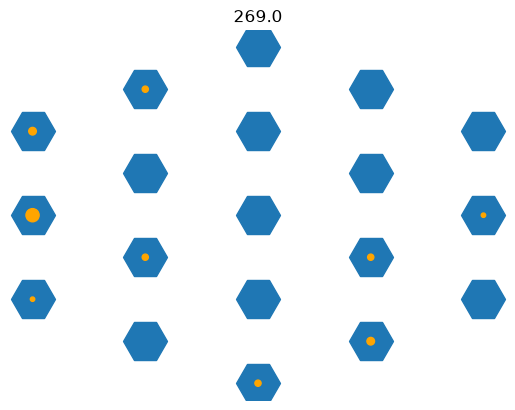

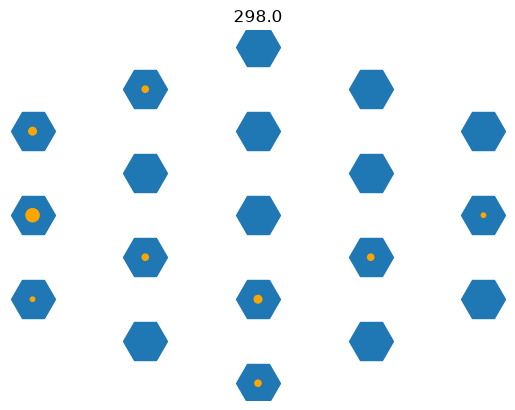

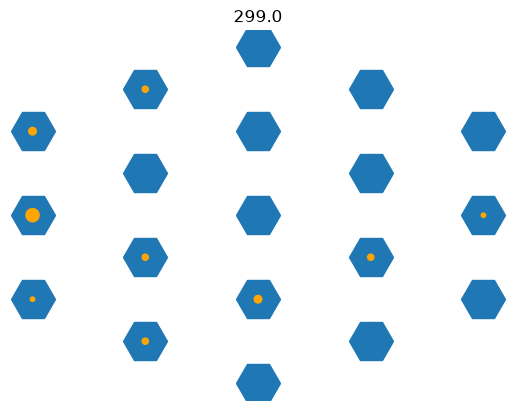

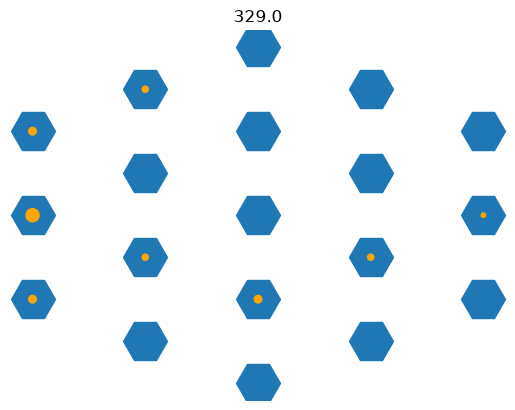

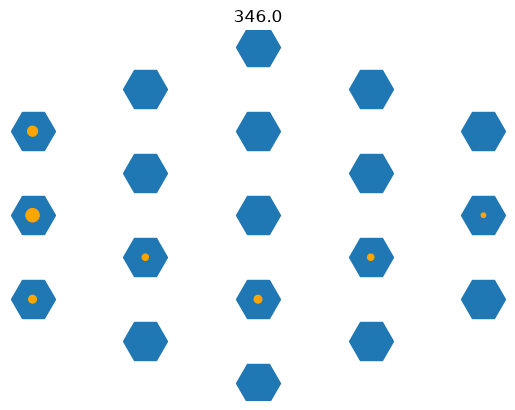

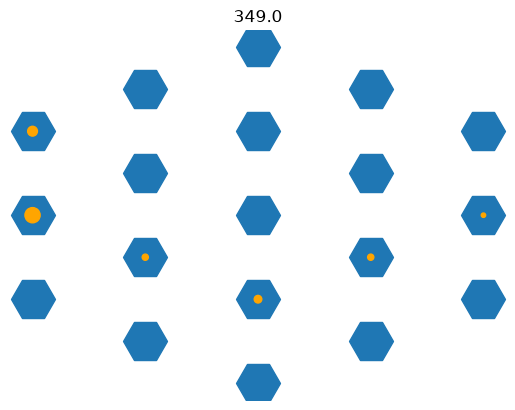

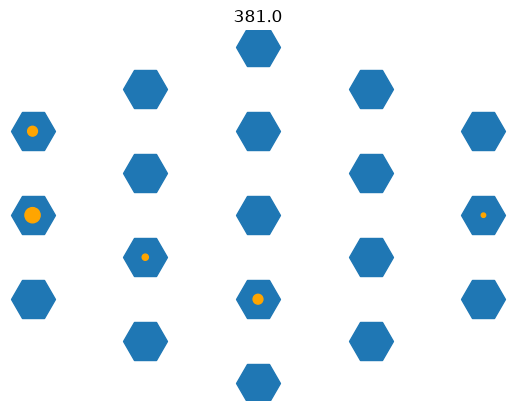

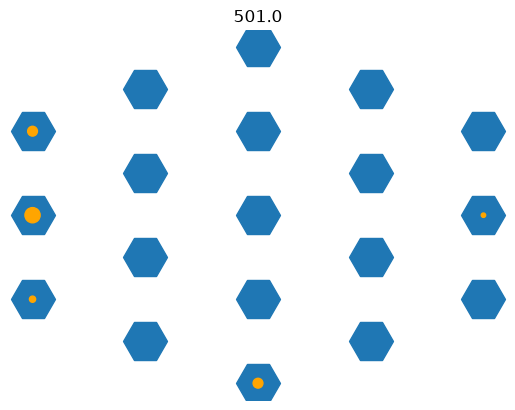

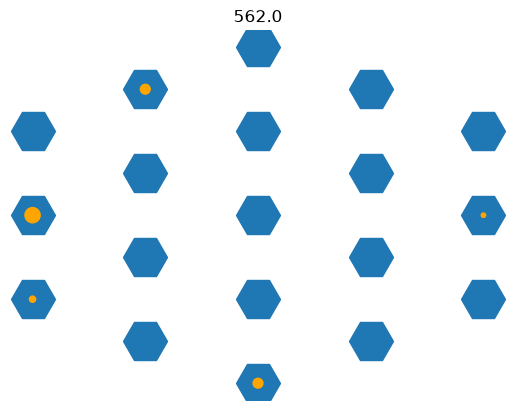

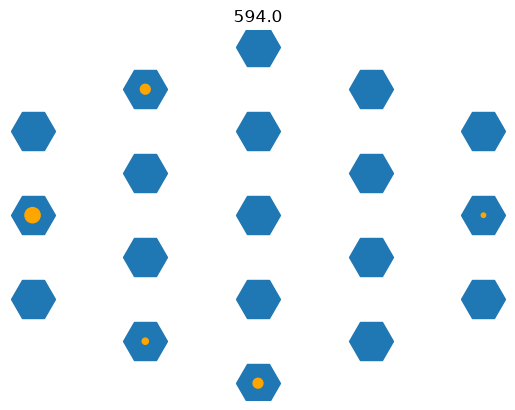

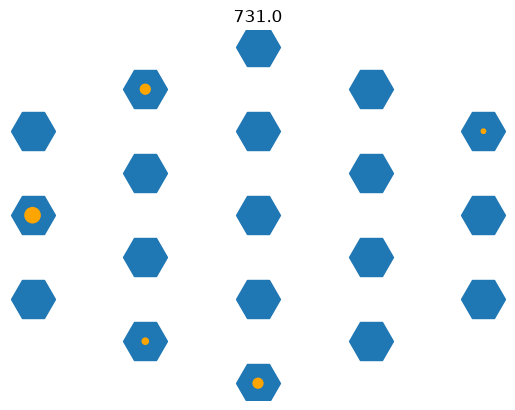

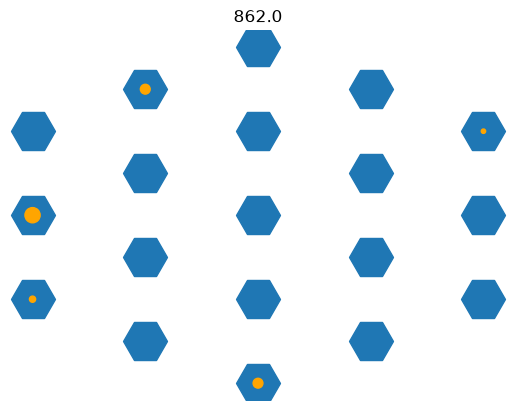

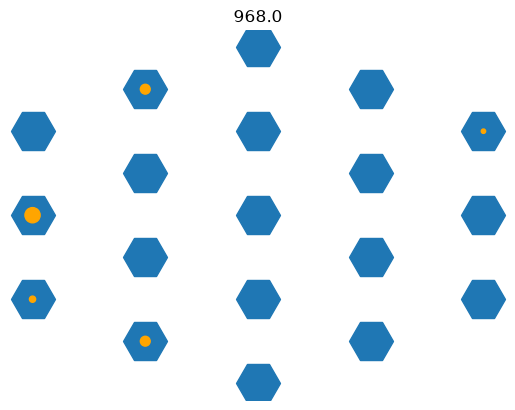

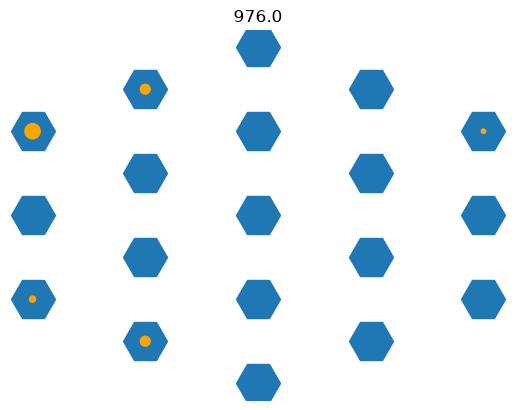

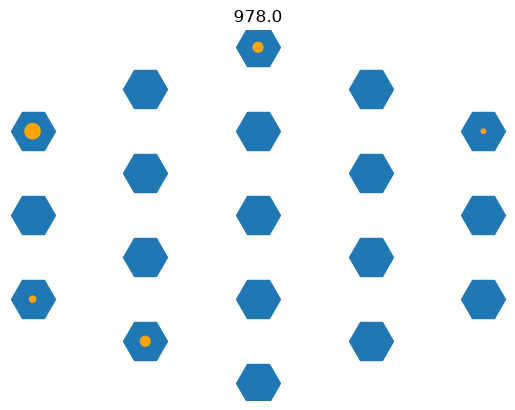

In [9]:
lineage = []
time = []
deme = []
tree = ts.first()
for sample in ts.samples():
    a = sample
    while a != -1:
        lineage.append(sample)
        time.append(ts.node(a).time)
        deme.append(int(ts.population(ts.node(a).population).metadata["name"][1:]) % len(world_map.demes))
        a = tree.parent(a)

locations = pd.DataFrame({"lineage":lineage, "time":time, "deme":deme})

previous_counts = None
for time, group in locations.groupby("time"):
    
    counts = group["deme"].value_counts()
    if (not counts.equals(previous_counts)):

        xs = []
        ys = []
        ss = []
        for i,row in world_map.demes.iterrows():
            if row["id"] in counts:
                xs.append(row["xcoord"])
                ys.append(row["ycoord"])
                ss.append(counts[row["id"]]*10)
        
        plt.scatter(world_map.demes["xcoord"], world_map.demes["ycoord"], s=1000, marker="H")
        plt.scatter(xs, ys, s=ss, color="orange", zorder=20, label="Lineages")
        
        plt.title(time)
        plt.axis("off")
        plt.show()

        previous_counts = counts

In [4]:
for t in range(0, 2100, 100):
    filtered = locations.loc[locations["time"]<=t]
    filled_demes = list(filtered.loc[filtered.groupby("lineage")["time"].idxmax()]["deme"])
    for i,row in demes.iterrows():
        count = filled_demes.count(i)
        if count > 0:
            print(int(world_map.get_deme_suitability_at_time(row["id"], t)*15))

15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
7
10
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
10
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
7
10
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
15
